In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, os

# Add the parent directory (project_root) to sys.path
PARENT_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PARENT_DIR not in sys.path:
    sys.path.append(PARENT_DIR)


import numpy as np
import pandas as pd
from gt_concepts.least_core import exact_least_core


from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split


# Utility wrapper for least core (regression)

class _FeatureDataWrapper:
    """Wrapper so least_core.exact_least_core can query feature names."""
    def __init__(self, feature_names):
        self.data_names = list(feature_names)

    def __len__(self):
        return len(self.data_names)


class RegressionFeatureUtility:
    """
    Cooperative game for regression:
        - Players = features (columns of X)
        - Coalition S (list of indices) = subset of features
        - v(S) = average predicted target when only features in S
                are kept from X_test and others are set to a baseline.
    """
    def __init__(self, model, X_train, X_test, feature_names):
        self.model = model
        self.X_train = X_train.reset_index(drop=True)
        self.X_test = X_test.reset_index(drop=True)
        self.feature_names = list(feature_names)
        self.data = _FeatureDataWrapper(self.feature_names)

        # Baseline value for missing features (mean over training data)
        self.baseline = self.X_train.mean(axis=0).values

    def __call__(self, coalition):
        coalition = list(coalition)

        if not coalition:
            # empty coalition = no predictive power
            return 0.0

        # Start from baseline matrix
        X_masked = np.tile(self.baseline, (self.X_test.shape[0], 1))

        # Put back the "active" coalition features from X_test
        X_masked[:, coalition] = self.X_test.iloc[:, coalition].values

        # Predict and take mean prediction as coalition value
        preds = self.model.predict(X_masked)
        return float(preds.mean())


# Least-Core attribution for regression

def compute_least_core_attribution_reg(model, X_train, X_test, feature_names, solver=None):
    """
    Returns: pd.Series of least-core attributions for a regression model.
    """
    utility = RegressionFeatureUtility(model, X_train, X_test, feature_names)

    options = {}
    if solver:
        options["solver"] = solver  # e.g. "ECOS", "SCS"

    result = exact_least_core(utility, options=options)
    return pd.Series(result.values, index=feature_names, name="LeastCore")


def load_regression_csv(path, target_col=None, test_size=0.25, random_state=42):
    """
    Load a CSV, drop 'Unnamed' index columns, split into train/test.
    If target_col is None, use the last column as target.
    """
    df = pd.read_csv(path)

    # Drop index-like columns such as 'Unnamed: 0'
    df = df.loc[:, ~df.columns.str.contains(r'^Unnamed')]

    if target_col is None:
        target_col = df.columns[-1]

    y = df[target_col].values
    X = df.drop(columns=[target_col])

    feature_names = list(X.columns)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    return X_train, X_test, y_train, y_test, feature_names


def run_least_core_on_csv(path, target_col, dataset_name):
    print("\n" + "=" * 72)
    print(f"Least-Core (regression) on: {dataset_name}")
    print("=" * 72)

    X_train, X_test, y_train, y_test, feature_names = load_regression_csv(
        path, target_col=target_col
    )

    # Train regression model (RF is robust for these synthetic datasets)
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        random_state=42,
    )
    model.fit(X_train, y_train)

    # Compute least-core attributions
    leastcore_values = compute_least_core_attribution_reg(
        model,
        X_train,
        X_test,
        feature_names,
        solver=None,
    )

    print("\n===== Least-Core Attributions =====")
    print(leastcore_values.sort_values(ascending=False))
    return leastcore_values


if __name__ == "__main__":
    LUNG_PATH = "../datasets/lung_cancer_risk.csv"
    CV_PATH   = "../datasets/cv_risk.csv"

    # Lung cancer: target column is 'lung_cancer_risk'
    lung_leastcore = run_least_core_on_csv(
        LUNG_PATH,
        target_col="lung_cancer_risk",
        dataset_name="synthetic_lung_cancer_risk",
    )

    # Cardiovascular risk: target column is 'cv_risk'
    cv_leastcore = run_least_core_on_csv(
        CV_PATH,
        target_col="cv_risk",
        dataset_name="synthetic_cardiovascular_risk",
    )


Least-Core (regression) on: synthetic_lung_cancer_risk

===== Least-Core Attributions =====
stress          5.631158
drink_coffee    5.386978
smoking         4.969614
Name: LeastCore, dtype: float64

Least-Core (regression) on: synthetic_cardiovascular_risk

===== Least-Core Attributions =====
family_history    3.108818
diet_score        2.885554
sleep_duration    2.681135
bmi               2.497536
Name: LeastCore, dtype: float64


In [2]:
lung_leastcore = pd.Series(
    {"stress": 5.632003, "drink_coffee": 5.385968, "smoking": 4.969220},
    name="LeastCore"
)

cv_leastcore = pd.Series(
    {
        "family_history": 3.109386,
        "diet_score": 2.886495,
        "sleep_duration": 2.680939,
        "bmi": 2.496410
    },
    name="LeastCore"
)

In [3]:
import matplotlib.pyplot as plt

def plot_least_core_vertical(lc_series, title, filename=None):
    """
    lc_series: pd.Series (index = feature names, values = least-core scores)
    Creates a vertical bar plot.
    """

    s = lc_series.sort_values(ascending=False)   # highest at the top

    plt.figure(figsize=(7, 5))
    plt.bar(s.index, s.values, color="#4C72B0")

    plt.ylabel("Least-Core Value", fontsize=12)
    plt.xlabel("Feature", fontsize=12)
    plt.title(title, fontsize=14, fontweight="bold")

    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    if filename:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()

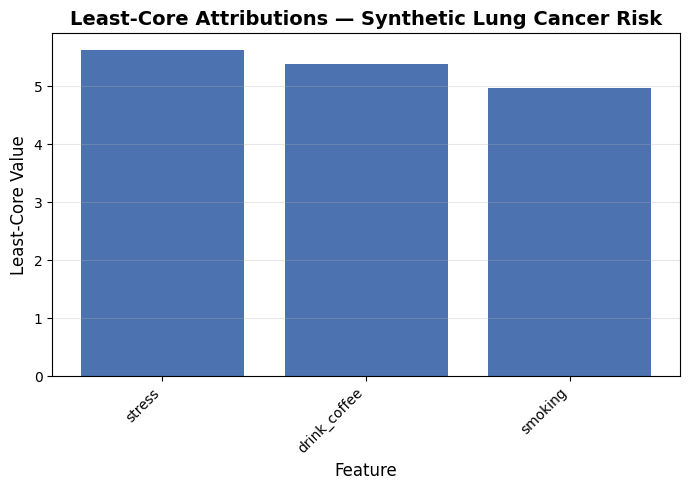

In [4]:
plot_least_core_vertical(
    lung_leastcore,
    title="Least-Core Attributions — Synthetic Lung Cancer Risk",
    filename="leastcore_lung_vertical.png"
)

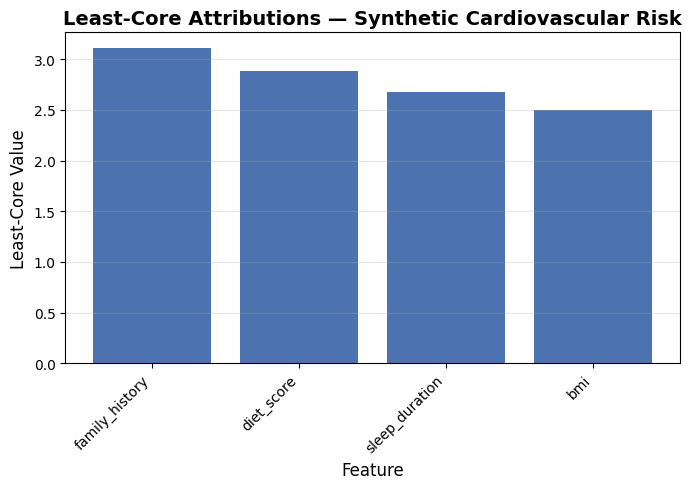

In [5]:
plot_least_core_vertical(
    cv_leastcore,
    title="Least-Core Attributions — Synthetic Cardiovascular Risk",
    filename="leastcore_cv_vertical.png"
)